# Vision Transformers (ViT) con y sin YOLO.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
import timm
from timm.optim import param_groups_layer_decay
from timm.scheduler.cosine_lr import CosineLRScheduler

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"; print(device)

CACHE, RES = "cache", "resultados"
meta = pd.read_csv(f"{CACHE}/meta.csv")
M = {s: meta[meta.subset == s].reset_index(drop=True) for s in ["train", "val", "test"]}
NUM_WORKERS = 6
SEED = 23
assert os.path.exists(f"{CACHE}/det.csv"), "los recortes se generan en el experimento 4"

def fijar_semilla(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

cuda


In [2]:
def evaluate_clock(yh, ym, ph, pm, tol=2):
    yh, ym, ph, pm = (np.asarray(v).astype(int) for v in (yh, ym, ph, pm))
    valid = ph >= 0
    hour_ok = valid & (ph == yh)
    dm = np.abs(pm - ym) % 60; dm = np.minimum(dm, 60 - dm)
    min_ok = valid & (dm <= tol)
    dt = np.abs(np.where(valid, ph * 60 + pm, 0) - (yh * 60 + ym)) % 720; dt = np.minimum(dt, 720 - dt)
    return {"hour_acc": 100 * hour_ok.mean(), "min_acc": 100 * min_ok.mean(),
            "full_acc": 100 * (hour_ok & min_ok).mean(), "exact_acc": 100 * (hour_ok & (pm == ym)).mean(),
            "mae": dt.mean()}

def guardar_pred(nombre, split, m, ph, pm, logp=None):
    df = pd.DataFrame({"idx": m.idx.values, "hour": m.hour.values, "minute": m.minute.values,
                       "pred_hour": np.asarray(ph), "pred_minute": np.asarray(pm)})
    df.to_csv(f"{RES}/{nombre}_{split}.csv", index=False)
    r = evaluate_clock(df.hour, df.minute, df.pred_hour, df.pred_minute)
    print(f"{nombre:28s} {split:5s} | hora {r['hour_acc']:6.2f} | min±2 {r['min_acc']:6.2f} | "
          f"completa {r['full_acc']:6.2f} | MAE {r['mae']:6.1f}")
    return r

In [3]:
def hflip_label(h, m):
    t = (720 - (60 * h + m)) % 720
    return t // 60, t % 60

class ClockDataset(Dataset):
    def __init__(self, meta, folder, transform=None, hflip=0.0):
        self.meta = meta.reset_index(drop=True)
        self.folder = folder
        self.transform = transform
        self.hflip = hflip

    def __len__(self):
        return len(self.meta)

    def __getitem__(self, idx):
        r = self.meta.iloc[idx]
        image = Image.open(f"{CACHE}/{self.folder}/{r.split}_{r.idx}.jpg").convert("RGB")
        h, m = int(r.hour), int(r.minute)
        if self.hflip > 0 and torch.rand(1).item() < self.hflip:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            h, m = hflip_label(h, m)
        if self.transform:
            image = self.transform(image)
        return {"X": image, "y": torch.tensor(60 * h + m)}

def make_transform(res, mean, std, train=False):
    if not train:
        return transforms.Compose([transforms.Resize((res, res), interpolation=transforms.InterpolationMode.BICUBIC),
                                   transforms.ToTensor(), transforms.Normalize(mean, std)])
    return transforms.Compose([
        transforms.RandomResizedCrop(res, scale=(0.65, 1.0), ratio=(0.85, 1.18), interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.RandomApply([transforms.RandomRotation(10)], p=0.5),
        transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.3, 0.05)], p=0.8),
        transforms.RandomGrayscale(0.1),
        transforms.RandomApply([transforms.GaussianBlur(5, (0.1, 1.5))], p=0.2),
        transforms.ToTensor(), transforms.Normalize(mean, std)])

def loss_fn(pred, y, smoothing=0.05):
    pred = pred.float()
    return (F.cross_entropy(pred[:, :12], y // 60, label_smoothing=smoothing)
            + F.cross_entropy(pred[:, 12:72], y % 60, label_smoothing=smoothing))

def joint_logp(pred):
    pred = pred.float()
    return (F.log_softmax(pred[:, :12], 1)[:, :, None] + F.log_softmax(pred[:, 12:72], 1)[:, None, :]).reshape(-1, 720)

FLIP_PERM = torch.tensor([60 * hflip_label(t // 60, t % 60)[0] + hflip_label(t // 60, t % 60)[1] for t in range(720)])

def predict(model, loader, tta=False):
    model.eval()
    LP = []
    with torch.no_grad():
        for batch in loader:
            X = batch["X"].to(device)
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=device == "cuda"):
                lp = joint_logp(model(X))
                if tta:
                    lf = joint_logp(model(torch.flip(X, dims=[3])))
                    back = torch.empty_like(lf); back[:, FLIP_PERM.to(device)] = lf
                    lp = lp + back
            LP.append(lp.float().cpu())
    LP = torch.cat(LP).numpy()
    t = LP.argmax(1)
    return t // 60, t % 60, LP

In [4]:
def exp(model, device, train_loader, val_loader, optimizer, scheduler, epochs=15, ckpt="model.pth"):
    step, best, hist = 0, -1, []
    vm = val_loader.dataset.meta
    for epoch in range(epochs):
        t0 = time.time()
        print(f'Epoch {epoch}: train:', end=' ')
        model.train(); trbatches, trloss = 0, 0
        for batch in train_loader:
            X, y = batch['X'].to(device), batch['y'].to(device); trbatches += 1
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=device == "cuda"):
                pred = model(X)
            loss = loss_fn(pred, y); trloss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); optimizer.zero_grad(); step += 1
            scheduler.step_update(num_updates=step)
        trloss /= trbatches
        ph, pm, _ = predict(model, val_loader)
        r = evaluate_clock(vm.hour, vm.minute, ph, pm)
        print(f"loss {trloss:.4f} val: hora {r['hour_acc']:.2f}% min±2 {r['min_acc']:.2f}% completa {r['full_acc']:.2f}% "
              f"MAE {r['mae']:.1f} ({time.time() - t0:.0f}s)")
        hist.append({"epoch": epoch, "loss": trloss, **r})
        score = r["full_acc"] + r["hour_acc"] / 100
        if score > best:
            best = score
            torch.save(model.state_dict(), ckpt)
    return pd.DataFrame(hist)

## Entrenamiento de un ViT

In [5]:
# layer-wise lr decay: la cabeza aprende con lr y cada bloque
# hacia la entrada con lr * decay^k, porque las primeras capas deben cambiar menos
def entrenar_vit(model_name, folder, nombre, res=384, epochs=12, lr=1e-4, layer_decay=0.75, batch_size=16):
    fijar_semilla()
    model = timm.create_model(model_name, pretrained=True, num_classes=72, drop_path_rate=0.1).to(device)
    cfg = timm.data.resolve_data_config(model.pretrained_cfg)
    print(f"{model_name}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parámetros, {res}x{res}, "
          f"parches de {model.patch_embed.patch_size}")
    kw = dict(num_workers=NUM_WORKERS, pin_memory=True)
    train_loader = DataLoader(ClockDataset(M["train"], folder, make_transform(res, cfg["mean"], cfg["std"], True), 0.5),
                              batch_size=batch_size, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(SEED), **kw)
    ev = make_transform(res, cfg["mean"], cfg["std"])
    val_loader = DataLoader(ClockDataset(M["val"], folder, ev), batch_size=2 * batch_size, **kw)
    test_loader = DataLoader(ClockDataset(M["test"], folder, ev), batch_size=2 * batch_size, **kw)
    groups = param_groups_layer_decay(model, weight_decay=0.05, layer_decay=layer_decay)
    for g in groups:
        g["lr"] = lr * g.pop("lr_scale")
    optimizer = torch.optim.AdamW(groups)
    scheduler = CosineLRScheduler(optimizer, t_initial=epochs * len(train_loader), warmup_t=len(train_loader),
                                  warmup_lr_init=1e-7, lr_min=1e-7, t_in_epochs=False)
    hist = exp(model, device, train_loader, val_loader, optimizer, scheduler, epochs, ckpt=f"{nombre}.pth")
    model.load_state_dict(torch.load(f"{nombre}.pth", weights_only=True))
    for s, dl in [("val", val_loader), ("test", test_loader)]:
        guardar_pred(nombre, s, dl.dataset.meta, *predict(model, dl))
        guardar_pred(nombre + "_tta", s, dl.dataset.meta, *predict(model, dl, tta=True))
    print(f"memoria máxima de GPU: {torch.cuda.max_memory_allocated() / 2**30:.1f} GB")
    del model, optimizer; torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    return hist

## ViT-B/16 (86 M, ImageNet-21k, 384 px)

In [6]:
hist = {}

In [7]:
hist["vit_b_full"] = entrenar_vit("vit_base_patch16_384.augreg_in21k_ft_in1k", "full", "vit_base_full")

vit_base_patch16_384.augreg_in21k_ft_in1k: 86.1 M parámetros, 384x384, parches de (16, 16)
Epoch 0: train: loss 6.9170 val: hora 9.79% min±2 12.68% completa 1.20% MAE 190.9 (78s)
Epoch 1: train: loss 5.5508 val: hora 16.21% min±2 21.59% completa 3.77% MAE 162.8 (82s)
Epoch 2: train: loss 4.9158 val: hora 23.52% min±2 33.71% completa 9.47% MAE 150.8 (82s)
Epoch 3: train: loss 4.2096 val: hora 28.81% min±2 38.36% completa 12.84% MAE 133.2 (83s)
Epoch 4: train: loss 3.7581 val: hora 30.98% min±2 42.22% completa 15.97% MAE 130.5 (82s)
Epoch 5: train: loss 3.5442 val: hora 32.74% min±2 43.98% completa 18.38% MAE 122.1 (83s)
Epoch 6: train: loss 3.3436 val: hora 31.86% min±2 45.51% completa 19.18% MAE 128.6 (82s)
Epoch 7: train: loss 3.1662 val: hora 34.19% min±2 45.10% completa 20.06% MAE 122.6 (82s)
Epoch 8: train: loss 3.0294 val: hora 35.39% min±2 45.59% completa 21.19% MAE 119.1 (82s)
Epoch 9: train: loss 2.9565 val: hora 35.23% min±2 45.83% completa 21.19% MAE 120.6 (82s)
Epoch 10: tra

In [8]:
hist["vit_b_crop"] = entrenar_vit("vit_base_patch16_384.augreg_in21k_ft_in1k", "crop", "vit_base_crop")

vit_base_patch16_384.augreg_in21k_ft_in1k: 86.1 M parámetros, 384x384, parches de (16, 16)
Epoch 0: train: loss 6.8442 val: hora 21.11% min±2 22.47% completa 3.93% MAE 146.9 (83s)
Epoch 1: train: loss 5.2096 val: hora 37.32% min±2 48.88% completa 19.18% MAE 105.5 (81s)
Epoch 2: train: loss 3.9139 val: hora 69.42% min±2 75.04% completa 55.54% MAE 48.3 (82s)
Epoch 3: train: loss 3.2467 val: hora 72.63% min±2 80.34% completa 62.28% MAE 40.4 (81s)
Epoch 4: train: loss 2.9010 val: hora 79.70% min±2 82.34% completa 70.14% MAE 29.3 (82s)
Epoch 5: train: loss 2.6856 val: hora 81.30% min±2 84.99% completa 73.52% MAE 27.0 (81s)
Epoch 6: train: loss 2.4851 val: hora 81.94% min±2 85.31% completa 74.24% MAE 28.5 (82s)
Epoch 7: train: loss 2.3406 val: hora 82.74% min±2 86.52% completa 75.76% MAE 26.3 (81s)
Epoch 8: train: loss 2.2380 val: hora 83.63% min±2 86.68% completa 76.24% MAE 24.6 (82s)
Epoch 9: train: loss 2.1415 val: hora 84.51% min±2 86.44% completa 77.29% MAE 23.7 (82s)
Epoch 10: train: l

## Resumen

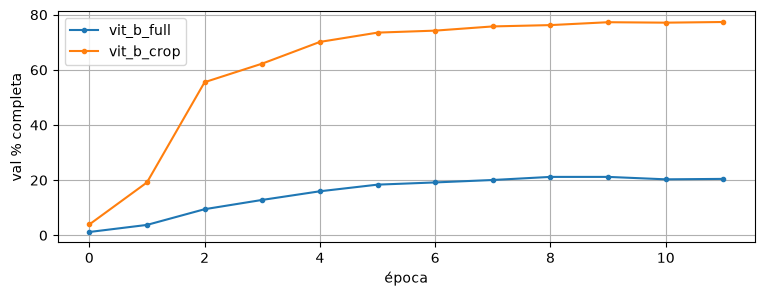

,tipo,entrada,val_full,hour_acc,min_acc,full_acc,exact_acc,mae
modelo,,,,,,,,
timm_resnet50,CNN,completa,16.05,37.15,46.86,25.08,9.62,111.74
timm_convnext_full,CNN,completa,33.15,54.93,64.27,44.37,19.00,76.32
timm_convnext_full_tta,CNN,completa,36.60,57.73,66.46,47.57,21.82,71.55
timm_convnext_crop,CNN,recorte,76.00,78.43,81.67,71.45,36.29,32.44
timm_convnext_crop_tta,CNN,recorte,78.09,80.54,82.41,73.93,39.17,29.45
vit_base_full,ViT,completa,21.19,46.31,55.80,33.89,14.18,98.05
vit_base_full_tta,ViT,completa,22.79,48.16,57.77,36.17,16.96,93.87
vit_base_crop,ViT,recorte,77.37,80.64,84.37,74.25,39.15,30.14
vit_base_crop_tta,ViT,recorte,78.49,81.59,85.00,75.68,40.42,26.88


In [9]:
plt.figure(figsize=(9, 3)); plt.grid(True)
for k, h in hist.items():
    plt.plot(h.epoch, h.full_acc, 'o-', ms=3, label=k)
plt.xlabel("época"); plt.ylabel("val % completa"); plt.legend(); plt.show()

filas = []
for n, tipo, entrada in [("timm_resnet50", "CNN", "completa"), ("timm_convnext_full", "CNN", "completa"),
                         ("timm_convnext_full_tta", "CNN", "completa"), ("timm_convnext_crop", "CNN", "recorte"),
                         ("timm_convnext_crop_tta", "CNN", "recorte"),
                         ("vit_base_full", "ViT", "completa"), ("vit_base_full_tta", "ViT", "completa"),
                         ("vit_base_crop", "ViT", "recorte"), ("vit_base_crop_tta", "ViT", "recorte")]:
    if os.path.exists(f"{RES}/{n}_test.csv"):
        v, t = pd.read_csv(f"{RES}/{n}_val.csv"), pd.read_csv(f"{RES}/{n}_test.csv")
        filas.append({"modelo": n, "tipo": tipo, "entrada": entrada,
                      "val_full": evaluate_clock(v.hour, v.minute, v.pred_hour, v.pred_minute)["full_acc"],
                      **evaluate_clock(t.hour, t.minute, t.pred_hour, t.pred_minute)})
pd.DataFrame(filas).set_index("modelo").round(2)

## NOTA


Se reejecutó todo el código para verificar que funcionaba correctamente. Los resultados de recortes y ViT difieren un poco de los de la memoria, por ejemplo en la memoria el mejor valor reportado es de 75.20 por Vit+recortes, y en esta ejecución da 75.68. Pequeñas variaciones que no implican cambios en las conclusiones de la memoria, son de +-1 punto porcentual.